# Phase 7 — Prior Case Retrieval (PCR) from the Phase-1 Legal LM

**What this notebook produces:** 6 Codabench-ready zips in `/kaggle/working/submissions/`, each holding only `prediction.json` at the root:

| zip | system | counts toward §13.2 |
|---|---|---|
| `sub1_bm25.zip` | BM25 lexical baseline (safety net, also the hard-negative miner) | baseline |
| `sub2_partial_ft.zip` | Exp 1 — Partial / layer-wise fine-tuning of the Phase-1 LM | technique 1 |
| `sub3_lorma.zip` | Exp 2 — **LoRMA** (compulsory) | technique 2 |
| `sub4_ia3.zip` | Exp 3 — IA³ | technique 3 |
| `sub5_kd_student.zip` | Exp 4 — **Knowledge distillation** into a half-depth student | KD (mandatory) |
| `sub6_ensemble.zip` | Ensemble of Exp 1–4 + BM25 (best leaderboard candidate) | extra |

**Before running (Kaggle):**
1. Accelerator: **GPU T4 / P100**. Settings → **Internet ON** (needed only if the Phase-7 data isn't attached).
2. Inputs: keep `actualphase1result` (Phase-1 checkpoint) and `bpefile` (`bpe32k.json`).
3. Phase-7 data: either attach it as a Kaggle input (any folder with `train.json`, `train_candidates.json`, …), **or** leave Internet on and the notebook downloads it from `Exploration-Lab/CS-781-Capstone`. If that dataset is gated, add your Hugging Face token as a Kaggle secret named `HF_TOKEN` (Add-ons → Secrets).
4. Optional smoke test first: set `QUICK = True` in the next cell, *Run all* (~5–10 min), check the zips appear, then set it back to `False` and *Run all*.

Every model is initialised from the Phase-1 checkpoint. No other pretrained weights or external APIs are used (BM25 is a non-neural statistic).

In [1]:
import os, sys, re, json, glob, time, math, random, zipfile, gc, pickle, types, copy, shutil
from pathlib import Path
from collections import defaultdict, OrderedDict
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F

# ======================= settings you may change =======================
QUICK = False # True = fast end-to-end smoke test
DATA_DIR = os.environ.get('P7_DATA_DIR') or None     # folder containing train.json etc. (auto-found if None)
CKPT_PATH = os.environ.get('P7_CKPT') or None        # Phase-1 checkpoint file (auto-picked if None)
TOKENIZER_PATH = os.environ.get('P7_TOK') or None    # bpe32k.json (auto-found if None)
HF_REPO = 'Exploration-Lab/CS-781-Capstone'          # used only when the data is not attached
OVERRIDE = {}          # force architecture guesses, e.g. {'n_heads': 12, 'act': 'gelu', 'causal': True}
PHASE1_VAL_LOSS = 3.370  # your Phase-1 validation loss, used to sanity-check the loaded model

CHUNK_LEN = 512        # tokens per chunk (capped at the model's context length)
N_CHUNKS_EVAL = 4      # chunks per case at inference, spread evenly over the document
N_CHUNKS_TRAIN = 2     # chunks per case during training (first chunk + one random chunk)
MAX_DOC_TOKENS = 50000
TAU = 0.05             # contrastive temperature
BATCH_Q = 8            # queries per step; other queries' documents act as in-batch negatives
N_HARD = 1             # BM25 hard negatives per query
STEPS = 600            # optimisation steps per experiment
ENC_BS = 32            # encoding batch size
SUBMIT_HYBRID = True   # experiment zips = dense model fused with BM25 (weight tuned on dev)
MIN_DENSE_WEIGHT = 0.3 # ... but the experiment's own dense score always keeps >= 30% weight
RUN_NOKD_CONTROL = True  # also train the student without the teacher (shows what KD adds)
SEED = 42
# =======================================================================

INPUT_ROOTS = [r for r in os.environ.get('P7_INPUT_ROOTS', '/kaggle/input').split(':') if os.path.isdir(r)]
WORK = Path(os.environ.get('P7_WORK', '/kaggle/working' if os.path.isdir('/kaggle/working') else './p7_work'))
WORK.mkdir(parents=True, exist_ok=True)
SUB_DIR = WORK / 'submissions'; SUB_DIR.mkdir(exist_ok=True)
if QUICK:
    CHUNK_LEN, N_CHUNKS_EVAL, N_CHUNKS_TRAIN, STEPS, BATCH_Q, MAX_DOC_TOKENS = 128, 1, 1, 15, 4, 3000

def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
AMP = DEVICE.type == 'cuda'
SPLITS = ['train', 'dev', 'test']
RESULTS = []          # one row per system, becomes results.csv
DENSE = {}            # name -> split -> (n_query x n_candidate) cosine scores
print('device:', DEVICE, torch.cuda.get_device_name(0) if AMP else '', '| torch', torch.__version__, '| QUICK =', QUICK)
print('input roots:', INPUT_ROOTS, '| work dir:', WORK)

device: cuda Tesla T4 | torch 2.11.0+cu130 | QUICK = False
input roots: ['/kaggle/input'] | work dir: /kaggle/working


## 1. Find (or download) the Phase-7 data

In [2]:
def walk_files(roots):
    for r in roots:
        for dp, dn, fn in os.walk(r):
            for f in fn:
                yield os.path.join(dp, f)

def find_split_files(roots):
    files = list(walk_files(roots))
    by_dir = defaultdict(dict)
    for f in files:
        by_dir[os.path.dirname(f)][os.path.basename(f).lower()] = f
    out = {}
    for s in SPLITS:
        best = None
        for d, names in by_dir.items():
            if f'{s}.json' in names and f'{s}_candidates.json' in names:
                score = 2 * bool(re.search(r'pcr|phase[_\- ]?7', d, re.I))
                if best is None or score > best[0]:
                    best = (score, names[f'{s}.json'], names[f'{s}_candidates.json'])
        if best:
            out[s] = best[1:]
    return out

def hf_token():
    if os.environ.get('HF_TOKEN'):
        return os.environ['HF_TOKEN']
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret('HF_TOKEN')
    except Exception:
        return None

def hf_download(dest):
    from huggingface_hub import list_repo_files, hf_hub_download
    tok = hf_token()
    files = list_repo_files(HF_REPO, repo_type='dataset', token=tok)
    pcr_re = re.compile(r'pcr|phase[_\- ]?7', re.I)
    js = [f for f in files if pcr_re.search(f) and re.search(r'(^|/)(train|dev|test)(_candidates)?\.json$', f, re.I)]
    if js:
        print('downloading', js)
        for f in js:
            hf_hub_download(HF_REPO, f, repo_type='dataset', local_dir=dest, token=tok)
        return
    arch = [f for f in files if pcr_re.search(f) and re.search(r'\.(zip|tar|tgz|tar\.gz)$', f, re.I)]
    for f in arch:
        print('downloading archive', f)
        p = hf_hub_download(HF_REPO, f, repo_type='dataset', local_dir=dest, token=tok)
        shutil.unpack_archive(p, os.path.join(dest, 'extracted', Path(f).name.split('.')[0]))
    if not arch:
        print('No PCR files recognised in the repo. First 80 repo files:'); print('\n'.join(files[:80]))

FOUND = find_split_files([DATA_DIR] if DATA_DIR else INPUT_ROOTS)
if len(FOUND) < 3:
    dest = '/tmp/p7_data'
    FOUND = find_split_files([dest]) if os.path.isdir(dest) else {}
    if len(FOUND) < 3:
        print('Phase-7 data not attached -> trying Hugging Face', HF_REPO)
        try:
            hf_download(dest)
        except Exception as e:
            print('HF download failed:', repr(e)[:400])
        FOUND = find_split_files([dest]) if os.path.isdir(dest) else {}
if len(FOUND) < 3:
    raise RuntimeError(
        'Could not find train/dev/test (+ *_candidates.json). Fix ONE of these:\n'
        ' (a) Notebook settings -> Internet ON, and if the HF dataset is gated add Kaggle secret HF_TOKEN; or\n'
        ' (b) download Phase_7_PCR from https://huggingface.co/datasets/' + HF_REPO + ', upload it as a Kaggle dataset, '
        'add it as an input and re-run; or\n (c) set DATA_DIR to the folder that contains it. Found so far: ' + str(FOUND))
for s in SPLITS:
    print(f'{s:5s}', FOUND[s])

Phase-7 data not attached -> trying Hugging Face Exploration-Lab/CS-781-Capstone
downloading ['Phase_7_PCR/Dev/dev.json', 'Phase_7_PCR/Dev/dev_candidates.json', 'Phase_7_PCR/Test/test.json', 'Phase_7_PCR/Test/test_candidates.json', 'Phase_7_PCR/Train/train.json', 'Phase_7_PCR/Train/train_candidates.json']


dev.json:   0%|          | 0.00/5.87M [00:00<?, ?B/s]

Phase_7_PCR/Dev/dev_candidates.json: reconstructing file:   0%|          |  0.00B / 51.9MB            

Phase_7_PCR/Dev/dev_candidates.json: downloading bytes:           |  0.00B            

test.json:   0%|          | 0.00/9.34M [00:00<?, ?B/s]

Phase_7_PCR/Test/test_candidates.json: reconstructing file:   0%|          |  0.00B / 71.1MB            

... (2 outputs left out)

Phase_7_PCR/Train/train.json: downloading bytes:           |  0.00B            

Phase_7_PCR/Train/train_candidates.json: reconstructing file:   0%|          |  0.00B /  160MB            

Phase_7_PCR/Train/train_candidates.json: downloading bytes:           |  0.00B            

train ('/tmp/p7_data/Phase_7_PCR/Train/train.json', '/tmp/p7_data/Phase_7_PCR/Train/train_candidates.json')
dev   ('/tmp/p7_data/Phase_7_PCR/Dev/dev.json', '/tmp/p7_data/Phase_7_PCR/Dev/dev_candidates.json')
test  ('/tmp/p7_data/Phase_7_PCR/Test/test.json', '/tmp/p7_data/Phase_7_PCR/Test/test_candidates.json')


In [3]:
ID_KEYS = ('id', 'query_id', 'qid', 'case_id', 'doc_id', 'candidate_id', 'ID', 'Id', 'name')
REL_KEYS = ('relevant_candidates', 'relevant', 'relevant_cases', 'relevant_ids', 'positives', 'labels', 'label', 'citations', 'gold')
TEXT_KEYS = ('text', 'sentences', 'content', 'document', 'doc', 'body', 'case_text', 'judgment')

def read_json_any(p):
    with open(p, encoding='utf-8') as f:
        txt = f.read()
    try:
        return json.loads(txt)
    except json.JSONDecodeError:
        return [json.loads(l) for l in txt.splitlines() if l.strip()]

def to_text(x):
    if x is None: return ''
    if isinstance(x, str): return x
    if isinstance(x, dict):
        k = next((k for k in TEXT_KEYS if k in x), None)
        return to_text(x[k]) if k else ' '.join(to_text(v) for v in x.values() if isinstance(v, (str, list)))
    if isinstance(x, (list, tuple)): return ' '.join(to_text(s) for s in x)
    return str(x)

def to_rows(obj):
    if isinstance(obj, dict):
        tk = next((k for k in TEXT_KEYS if k in obj), None)
        ik = next((k for k in ID_KEYS if k in obj), None)
        if tk and ik and isinstance(obj[ik], (list, dict)) and len(obj[ik]) > 1:     # columnar layout
            col = lambda v: list(v.values()) if isinstance(v, dict) else v
            ids = col(obj[ik])
            cols = {k: col(v) for k, v in obj.items() if isinstance(v, (list, dict)) and len(v) == len(ids)}
            return [(str(ids[i]), {k: cols[k][i] for k in cols}) for i in range(len(ids))]
        if len(obj) <= 3 and not any(re.fullmatch(r'\d+', str(k)) for k in obj):  # wrapper like {"data": [...]}
            big = [v for v in obj.values() if isinstance(v, (list, dict)) and len(v) > 3]
            if big: return to_rows(max(big, key=len))
        return [(str(k), v) for k, v in obj.items()]
    if isinstance(obj, list):
        rows = []
        for i, r in enumerate(obj):
            ik = next((k for k in ID_KEYS if isinstance(r, dict) and k in r), None)
            rows.append((str(r[ik]) if ik else str(i), r))
        return rows
    raise ValueError(f'unexpected JSON type {type(obj)}')

def rec_text(r):
    if isinstance(r, dict):
        k = next((k for k in TEXT_KEYS if k in r), None)
        return to_text(r[k]) if k else ''
    return to_text(r)

def rec_rel(r):
    if not isinstance(r, dict): return None
    k = next((k for k in REL_KEYS if k in r), None)
    if k is None: return None
    v = r[k]
    if isinstance(v, dict): v = list(v.keys())
    if isinstance(v, (str, int)): v = [v]
    return [str(x) for x in v]

DATA, RAW_SAMPLE = {}, {}
for s in SPLITS:
    qrows = to_rows(read_json_any(FOUND[s][0])); crows = to_rows(read_json_any(FOUND[s][1]))
    RAW_SAMPLE[s] = (qrows[0], crows[0])
    cids = [i for i, _ in crows]; ctext = [rec_text(r) for _, r in crows]
    pool = set(cids)
    alias = {c.lstrip('0'): c for c in cids}
    qids, qtext, gold, miss = [], [], {}, 0
    for qid, r in qrows:
        qids.append(qid); qtext.append(rec_text(r))
        g = rec_rel(r)
        if g is not None:
            gg = []
            for x in g:
                x = x if x in pool else alias.get(x.lstrip('0'), x)
                if x in pool and x != qid: gg.append(x)
                else: miss += 1
            gold[qid] = list(dict.fromkeys(gg))
    DATA[s] = dict(qids=qids, qtext=qtext, cids=cids, ctext=ctext, gold=gold if gold else None, missing_gold=miss)

# QUICK mode: shrink train/dev (test always stays complete so the zips are valid)
if QUICK:
    for s, nq, extra in (('train', 40, 250), ('dev', 25, 250)):
        D = DATA[s]; keep_q = list(range(min(nq, len(D['qids']))))
        need = {c for i in keep_q for c in D['gold'][D['qids'][i]]} if D['gold'] else set()
        rest = [c for c in D['cids'] if c not in need]; random.Random(0).shuffle(rest)
        keep_c = need | set(rest[:extra]); ci = [i for i, c in enumerate(D['cids']) if c in keep_c]
        D['qids'] = [D['qids'][i] for i in keep_q]; D['qtext'] = [D['qtext'][i] for i in keep_q]
        D['cids'] = [D['cids'][i] for i in ci]; D['ctext'] = [D['ctext'][i] for i in ci]
        if D['gold']: D['gold'] = {q: D['gold'][q] for q in D['qids']}

for s in SPLITS:
    D = DATA[s]; D['cidx'] = {c: i for i, c in enumerate(D['cids'])}
    D['gold_idx'] = [[D['cidx'][c] for c in D['gold'][q]] for q in D['qids']] if D['gold'] else None
    nrel = [len(v) for v in D['gold'].values()] if D['gold'] else [0]
    print(f"{s:5s} queries={len(D['qids']):5d} candidates={len(D['cids']):6d} "
          f"avg gold/query={np.mean(nrel):.2f} (min {min(nrel)}, max {max(nrel)}) gold ids not in pool={D['missing_gold']} "
          f"avg query chars={np.mean([len(t) for t in D['qtext']]):.0f} avg cand chars={np.mean([len(t) for t in D['ctext']]):.0f}")
q0, c0 = RAW_SAMPLE['train']
print('\nraw train query sample  :', q0[0], str(q0[1])[:300])
print('raw train candidate     :', c0[0], str(c0[1])[:200])
print('test id examples:', DATA['test']['qids'][:3], '| candidate id examples:', DATA['test']['cids'][:3])

train queries=  827 candidates=  4320 avg gold/query=6.42 (min 0, max 52) gold ids not in pool=0 avg query chars=39345 avg cand chars=36422
dev   queries=  118 candidates=  1023 avg gold/query=8.25 (min 1, max 92) gold ids not in pool=0 avg query chars=48740 avg cand chars=49977
test  queries=  237 candidates=  1727 avg gold/query=0.00 (min 0, max 0) gold ids not in pool=0 avg query chars=38781 avg cand chars=40554

raw train query sample  : 0000000599 {'text': ['PETITIONER: <NAME> Vs. RESPONDENT: ROOP SINGH RATHORE & OTHERS(and connected appeal) DATE OF JUDGMENT: 07/05/1963 BENCH: <NAME>, S.K. BENCH: <NAME>, S.K. SINHA, BHUVNESHWAR P.(CJ) DAYAL, RAGHUBAR AYYANGAR, <NAME> MUDHOLKAR, J.R. CITATION: 1964 AIR 1545 1964 SCR (3) 573 CITATOR INFO : R 19
raw train candidate     : 0000000262 {'text': ['JUDGMENT <NAME>, C.J. ', '1. The only point which has to be considered in this appeal is whether or not the lower appellate Court was wrong in admitting in evidence statements contained in 
test

## 2. Load the Phase-1 Legal LM
The loader does not need your Phase-1 class: it reads the checkpoint (plain `state_dict`, a dict with `model`/`config`, or even a pickled model object whose class is missing), works out the transformer layout from parameter names and shapes, and rebuilds it. It then **checks the rebuilt model by measuring its next-token loss on legal text**: if the loss is close to your Phase-1 validation loss (3.37), the weights were loaded correctly. Where the layout is ambiguous (number of heads, activation, RoPE style, …) it tries the options and keeps the one with the lowest loss.

In [4]:
# ---------- checkpoint + tokenizer discovery / loading ----------
class _Stub:
    def __init__(self, *a, **k): pass
    def __setstate__(self, st):
        if isinstance(st, tuple) and len(st) == 2 and (st[0] is None or isinstance(st[0], dict)) and isinstance(st[1], dict):
            st = {**(st[0] or {}), **st[1]}
        if isinstance(st, dict): self.__dict__.update(st)
        else: self.__dict__['_state'] = st

class _LenientUnpickler(pickle.Unpickler):
    def find_class(self, module, name):
        try:
            return super().find_class(module, name)
        except Exception:
            return type(name, (_Stub,), {'__module__': 'stub_' + module})

lenient_pickle = types.ModuleType('lenient_pickle')
lenient_pickle.Unpickler = _LenientUnpickler
lenient_pickle.load = lambda f, **kw: _LenientUnpickler(f, **kw).load()
lenient_pickle.loads = lambda b, **kw: _LenientUnpickler(__import__('io').BytesIO(b), **kw).load()
lenient_pickle.UnpicklingError = pickle.UnpicklingError

def is_tensor_dict(d):
    return isinstance(d, dict) and len(d) >= 4 and sum(torch.is_tensor(v) for v in d.values()) >= 0.8 * len(d)

def module_tensors(o, prefix='', out=None, seen=None):
    out = {} if out is None else out; seen = set() if seen is None else seen
    if id(o) in seen: return out
    seen.add(id(o)); d = getattr(o, '__dict__', {})
    for n, p in (d.get('_parameters') or {}).items():
        if torch.is_tensor(p): out[prefix + n] = p.detach()
    for n, b in (d.get('_buffers') or {}).items():
        if torch.is_tensor(b): out[prefix + n] = b
    for n, m in (d.get('_modules') or {}).items():
        if m is not None: module_tensors(m, prefix + n + '.', out, seen)
    return out

def find_state_dict(obj, depth=0):
    if is_tensor_dict(obj): return {k: v for k, v in obj.items() if torch.is_tensor(v)}
    if '_modules' in getattr(obj, '__dict__', {}): return module_tensors(obj)
    if isinstance(obj, dict) and depth < 3:
        pref = ['model', 'model_state_dict', 'state_dict', 'model_state', 'net', 'module', 'weights', 'params']
        for k in pref + [k for k in obj if k not in pref]:
            if k in obj and not str(k).lower().startswith('optim'):
                r = find_state_dict(obj[k], depth + 1)
                if r: return r
    return None

def find_config(obj):
    cfg, queue, n = {}, [(obj, 0)], 0
    while queue and n < 20000:
        o, dp = queue.pop(0); n += 1
        if isinstance(o, dict): d = o
        elif hasattr(o, '__dict__') and not torch.is_tensor(o): d = vars(o)
        else: continue
        if is_tensor_dict(d): continue
        for k, v in list(d.items()):
            ks = str(k)
            if torch.is_tensor(v) or ks.lower().startswith(('optim', 'opt_', 'scheduler', 'scaler', '_parameters', '_buffers')): continue
            if isinstance(v, (bool, int, float, str)): cfg.setdefault(ks, v)
            elif dp < 12 and (isinstance(v, dict) or hasattr(v, '__dict__')): queue.append((v, dp + 1))
    return cfg

def cfg_get(cfg, names, default=None):
    low = {k.lower(): v for k, v in cfg.items()}
    for n in names:
        v = low.get(n)
        if isinstance(v, (int, float)) and not isinstance(v, bool): return v
    return default

def load_checkpoint(path):
    if path.endswith('.safetensors'):
        from safetensors.torch import load_file
        return load_file(path), {}
    try:
        obj = torch.load(path, map_location='cpu', weights_only=False)
    except Exception as e:
        print('plain torch.load failed (', repr(e)[:150], ') -> lenient unpickling')
        obj = torch.load(path, map_location='cpu', weights_only=False, pickle_module=lenient_pickle)
    sd = find_state_dict(obj)
    if not sd: raise RuntimeError(f'No weights found in {path}; top-level type {type(obj)} keys {list(obj)[:20] if isinstance(obj, dict) else ""}')
    return sd, find_config(obj)

def find_ckpt():
    files = [f for f in walk_files(INPUT_ROOTS) if os.path.getsize(f) > 1e5
             and not f.lower().endswith(('.json', '.jsonl', '.csv', '.txt', '.png', '.jpg', '.log', '.md', '.parquet', '.ipynb'))]
    print('candidate checkpoint files:')
    for f in files: print(f'  {os.path.getsize(f)/1e6:9.1f} MB  {f}')
    def score(f):
        n = os.path.basename(f).lower()
        return (10 * ('a_decoder' in n) + 2 * ('best' in n) + 2 * ('decoder' in n) - 6 * ('optim' in n), os.path.getsize(f))
    return max(files, key=score) if files else None

def bytes_to_unicode():
    bs = list(range(ord('!'), ord('~') + 1)) + list(range(ord('¡'), ord('¬') + 1)) + list(range(ord('®'), ord('ÿ') + 1))
    cs = bs[:]; n = 0
    for b in range(256):
        if b not in bs: bs.append(b); cs.append(256 + n); n += 1
    return dict(zip(bs, map(chr, cs)))

def load_tokenizer(path):
    from tokenizers import Tokenizer, models, pre_tokenizers, decoders
    try:
        tk = Tokenizer.from_file(path); print('tokenizer: HF tokenizers format, vocab', tk.get_vocab_size()); return tk
    except Exception as e:
        print('not a HF tokenizer.json (', repr(e)[:100], ') -> trying other BPE formats')
    data = json.load(open(path, encoding='utf-8'))
    if isinstance(data, dict) and isinstance(data.get('model'), dict): data = data['model']
    vocab = data.get('vocab') if isinstance(data, dict) else None
    merges = data.get('merges') if isinstance(data, dict) else None
    if isinstance(vocab, dict) and vocab and isinstance(next(iter(vocab.values())), int) and merges is not None:
        mg = [tuple(m.split(' ', 1)) if isinstance(m, str) else tuple(m) for m in merges]
        tk = Tokenizer(models.BPE(vocab, mg))
        keys = list(vocab)[:5000]
        if any('Ġ' in t for t in keys): tk.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False); tk.decoder = decoders.ByteLevel()
        elif any('▁' in t for t in keys): tk.pre_tokenizer = pre_tokenizers.Metaspace()
        else: tk.pre_tokenizer = pre_tokenizers.Whitespace()
        print('tokenizer: vocab+merges json, vocab', tk.get_vocab_size()); return tk
    if merges is not None:   # minbpe-style integer merges
        if isinstance(merges, dict): items = [(tuple(int(x) for x in re.findall(r'\d+', k))[:2], int(v)) for k, v in merges.items()]
        else: items = [((int(m[0]), int(m[1])), int(m[2]) if len(m) > 2 else 256 + i) for i, m in enumerate(merges)]
        items.sort(key=lambda x: x[1]); b2u = bytes_to_unicode()
        tb = {i: bytes([i]) for i in range(256)}
        for (a, b), idx in items: tb[idx] = tb[a] + tb[b]
        u = lambda bb: ''.join(b2u[c] for c in bb)
        tk = Tokenizer(models.BPE({u(bb): i for i, bb in tb.items()}, [(u(tb[a]), u(tb[b])) for (a, b), _ in items]))
        tk.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
        print('tokenizer: converted integer merges to byte-level BPE, vocab', tk.get_vocab_size()); return tk
    raise ValueError('Unrecognised tokenizer format; top-level keys: ' + str(list(data)[:20]))

if CKPT_PATH is None: CKPT_PATH = find_ckpt()
if TOKENIZER_PATH is None:
    toks = [f for f in walk_files(INPUT_ROOTS) if re.search(r'bpe.*\.json$|tokenizer\.json$', os.path.basename(f), re.I)]
    TOKENIZER_PATH = sorted(toks, key=lambda f: ('bpe32k' not in f.lower(), f))[0] if toks else None
print('\nPhase-1 checkpoint:', CKPT_PATH, '\ntokenizer:', TOKENIZER_PATH)
assert CKPT_PATH and TOKENIZER_PATH, 'Attach the Phase-1 checkpoint and bpe32k.json as inputs (or set CKPT_PATH / TOKENIZER_PATH).'
RAW_SD, RAW_CFG = load_checkpoint(CKPT_PATH)
TOK = load_tokenizer(TOKENIZER_PATH)
print(f'{len(RAW_SD)} tensors, {sum(v.numel() for v in RAW_SD.values())/1e6:.1f}M values; config found: '
      + str({k: v for k, v in RAW_CFG.items() if isinstance(v, (int, float)) and not isinstance(v, bool)})[:600])
for k in list(RAW_SD)[:40]: print('  ', k, tuple(RAW_SD[k].shape))
if len(RAW_SD) > 40: print('   ...')

candidate checkpoint files:
      268.2 MB  /kaggle/input/datasets/samswe/actualphase1result/__kaggle__working__ckpt__A_decoder.pt
      296.6 MB  /kaggle/input/datasets/samswe/actualphase1result/__kaggle__working__ckpt__B_encdec.pt
      277.7 MB  /kaggle/input/datasets/samswe/actualphase1result/__kaggle__working__ckpt__C_hybrid.pt
      221.1 MB  /kaggle/input/datasets/samswe/actualphase1result/__kaggle__working__ckpt__D_efficient.pt

Phase-1 checkpoint: /kaggle/input/datasets/samswe/actualphase1result/__kaggle__working__ckpt__A_decoder.pt 
tokenizer: /kaggle/input/datasets/samswe/bpefile/bpe32k.json
tokenizer: HF tokenizers format, vocab 32000
87 tensors, 134.1M values; config found: {}
   tok_emb.weight (32000, 768)
   blocks.0.norm1.weight (768,)
   blocks.0.attn.qkv.weight (2304, 768)
   blocks.0.attn.proj.weight (768, 768)
   blocks.0.norm2.weight (768,)
   blocks.0.mlp.w1.weight (2048, 768)
   blocks.0.mlp.w2.weight (2048, 768)
   blocks.0.mlp.w3.weight (768, 2048)
   blocks.1.

In [5]:
# ---------- a generic decoder that can hold the Phase-1 weights ----------
ACTS = {'gelu': F.gelu, 'gelu_tanh': lambda x: F.gelu(x, approximate='tanh'), 'relu': F.relu, 'silu': F.silu}

def _lin(wb):
    w, b = wb
    m = nn.Linear(w.shape[1], w.shape[0], bias=b is not None)
    with torch.no_grad():
        m.weight.copy_(w)
        if b is not None: m.bias.copy_(b)
    return m

class Norm(nn.Module):
    def __init__(self, w, b, cfg):
        super().__init__(); self.cfg = cfg
        self.weight = nn.Parameter(w.clone().float())
        self.bias = nn.Parameter(b.clone().float()) if b is not None else None
    def forward(self, x):
        if self.bias is not None or self.cfg['norm'] == 'ln':
            return F.layer_norm(x, (x.shape[-1],), self.weight, self.bias, self.cfg['eps'])
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.cfg['eps'])).to(x.dtype) * self.weight

def apply_rope(x, cos, sin, style):
    T, h = x.shape[2], x.shape[-1] // 2
    c, s = cos[:T].to(x.dtype), sin[:T].to(x.dtype)
    if style == 'half':
        x1, x2 = x[..., :h], x[..., h:]
        return torch.cat([x1 * c - x2 * s, x2 * c + x1 * s], -1)
    x1, x2 = x[..., 0::2], x[..., 1::2]
    return torch.stack([x1 * c - x2 * s, x2 * c + x1 * s], -1).flatten(-2)

class Attn(nn.Module):
    def __init__(self, q, k, v, o, cfg):
        super().__init__(); self.q, self.k, self.v, self.o, self.cfg = q, k, v, o, cfg
        self.ia3_k = None; self.ia3_v = None
    def forward(self, x, rope, mask):
        B, T, _ = x.shape; H = self.cfg['n_heads']
        q, k, v = self.q(x), self.k(x), self.v(x)
        if self.ia3_k is not None: k = k * self.ia3_k.to(k.dtype); v = v * self.ia3_v.to(v.dtype)
        hd = q.shape[-1] // H; Hkv = k.shape[-1] // hd
        q = q.view(B, T, H, hd).transpose(1, 2); k = k.view(B, T, Hkv, hd).transpose(1, 2); v = v.view(B, T, Hkv, hd).transpose(1, 2)
        if rope is not None:
            q = apply_rope(q, *rope, self.cfg['rope_style']); k = apply_rope(k, *rope, self.cfg['rope_style'])
        if Hkv != H:
            k = k.repeat_interleave(H // Hkv, 1); v = v.repeat_interleave(H // Hkv, 1)
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=self.cfg['causal'] and mask is None)
        return self.o(y.transpose(1, 2).reshape(B, T, H * hd))

class MLP(nn.Module):
    def __init__(self, fc_in, fc_gate, fc_out, cfg):
        super().__init__(); self.fc_in, self.fc_gate, self.fc_out, self.cfg = fc_in, fc_gate, fc_out, cfg
        self.ia3_ff = None
    def forward(self, x):
        act = ACTS[self.cfg['act']]
        if self.fc_gate is None: h = act(self.fc_in(x))
        elif self.cfg.get('gate_swap'): h = act(self.fc_in(x)) * self.fc_gate(x)
        else: h = act(self.fc_gate(x)) * self.fc_in(x)
        if self.ia3_ff is not None: h = h * self.ia3_ff.to(h.dtype)
        return self.fc_out(h)

def split_qkv(wb, d, H, layout):
    w, b = wb; dkv = (w.shape[0] - d) // 2
    if layout == 'per_head' and dkv == d:
        hd = d // H; W = w.view(H, 3, hd, -1); Bv = b.view(H, 3, hd) if b is not None else None
        return [(W[:, i].reshape(d, -1), Bv[:, i].reshape(d) if Bv is not None else None) for i in range(3)]
    ws = torch.split(w, [d, dkv, dkv], 0); bs = torch.split(b, [d, dkv, dkv], 0) if b is not None else (None,) * 3
    return list(zip(ws, bs))

class Block(nn.Module):
    def __init__(self, L, cfg, d):
        super().__init__(); self.cfg = cfg
        q, k, v = split_qkv(L['qkv'], d, cfg['n_heads'], cfg.get('qkv_layout', 'concat')) if L.get('qkv') is not None else (L['q'], L['k'], L['v'])
        self.attn = Attn(_lin(q), _lin(k), _lin(v), _lin(L['o']), cfg)
        self.mlp = MLP(_lin(L['in']), _lin(L['gate']) if L.get('gate') is not None else None, _lin(L['out']), cfg)
        self.n1 = Norm(*L['n1'], cfg); self.n2 = Norm(*L['n2'], cfg)
    def forward(self, x, rope, mask):
        if self.cfg['prenorm']:
            x = x + self.attn(self.n1(x), rope, mask)
            return x + self.mlp(self.n2(x))
        x = self.n1(x + self.attn(x, rope, mask))
        return self.n2(x + self.mlp(x))

class Phase1Encoder(nn.Module):
    # Phase-1 LM body; forward returns the final hidden states (B, T, d)
    def __init__(self, spec, cfg):
        super().__init__(); self.cfg = dict(cfg); cfg = self.cfg
        self.d = spec['d']; self.grad_ckpt = False
        self.wte = nn.Embedding.from_pretrained(spec['wte'].clone(), freeze=False)
        self.wpe = nn.Embedding.from_pretrained(spec['wpe'].clone(), freeze=False) if (spec.get('wpe') is not None and cfg['pos'] == 'learned') else None
        self.emb_norm = Norm(*spec['emb_norm'], cfg) if spec.get('emb_norm') else None
        self.blocks = nn.ModuleList([Block(L, cfg, self.d) for L in spec['layers']])
        self.ln_f = Norm(*spec['final_norm'], cfg) if spec.get('final_norm') else None
        self.inv_freq = spec.get('inv_freq'); self._rope_cache = None
    def rope(self, T, device):
        if self._rope_cache is None or self._rope_cache[0].shape[0] < T or self._rope_cache[0].device != device:
            hd = self.blocks[0].attn.q.weight.shape[0] // self.cfg['n_heads'] if hasattr(self.blocks[0].attn.q, 'weight') else self.d // self.cfg['n_heads']
            inv = self.inv_freq if self.inv_freq is not None else 1.0 / (self.cfg['rope_theta'] ** (torch.arange(0, hd, 2).float() / hd))
            f = torch.outer(torch.arange(max(T, 2048)).float(), inv.float())
            self._rope_cache = (f.cos().to(device), f.sin().to(device))
        return self._rope_cache
    def forward(self, ids, pad_mask=None):
        B, T = ids.shape; cfg = self.cfg
        x = self.wte(ids) * cfg['emb_scale']
        if self.wpe is not None: x = x + self.wpe(torch.arange(T, device=ids.device))[None]
        if self.emb_norm is not None: x = self.emb_norm(x)
        rope = self.rope(T, ids.device) if cfg['pos'] == 'rope' else None
        mask = pad_mask[:, None, None, :].bool() if (not cfg['causal'] and pad_mask is not None) else None
        for blk in self.blocks:
            if self.grad_ckpt and self.training and torch.is_grad_enabled():
                x = torch.utils.checkpoint.checkpoint(blk, x, rope, mask, use_reentrant=False)
            else:
                x = blk(x, rope, mask)
        return self.ln_f(x) if self.ln_f is not None else x

In [6]:
# ---------- infer the layout from the state_dict ----------
QRE = re.compile(r'^(w_?)?q(uery)?(_?proj|_lin|_linear)?$|^to_q$', re.I)
KRE = re.compile(r'^(w_?)?k(ey)?(_?proj|_lin|_linear)?$|^to_k$', re.I)
VRE = re.compile(r'^(w_?)?v(alue)?(_?proj|_lin|_linear)?$|^to_v$', re.I)
QKVRE = re.compile(r'qkv|c_attn|in_proj|query_key_value|wqkv|att_proj', re.I)
ATTN_RE = re.compile(r'att|(^|\.)sa(\.|$)|mha|self_attn|attention', re.I)
MLP_RE = re.compile(r'mlp|ffn|ffwd|feed|(^|\.)ff(\.|$)', re.I)
N1 = {'ln_1', 'ln1', 'norm1', 'norm_1', 'attn_norm', 'attention_norm', 'input_layernorm', 'ln_attn', 'pre_norm', 'layernorm1', 'norm_attn', 'attn_ln'}
N2 = {'ln_2', 'ln2', 'norm2', 'norm_2', 'ffn_norm', 'mlp_norm', 'post_attention_layernorm', 'ln_mlp', 'layernorm2', 'norm_ff', 'ffn_ln', 'ff_norm', 'mlp_ln'}
SKIP = {'tril', 'mask', 'masked_bias', 'causal_mask', 'inv_freq', 'cos_cached', 'sin_cached', 'freqs_cis', 'attn_mask'}

def merge_per_head(lt):
    # Karpathy-style heads.0.key.weight ... -> key.weight (concatenated), returns (dict, n_heads)
    grp, out, nh = defaultdict(dict), {}, None
    for n, t in lt.items():
        m = re.match(r'^(.*)\.(\d+)\.([^.]+)\.(weight|bias)$', n)
        if m and (QRE.match(m.group(3)) or KRE.match(m.group(3)) or VRE.match(m.group(3))):
            grp[(m.group(1), m.group(3), m.group(4))][int(m.group(2))] = t
        else:
            out[n] = t
    for (p, nm, kind), heads in grp.items():
        out[f'{p}.{nm}.{kind}'] = torch.cat([heads[i] for i in sorted(heads)], 0); nh = len(heads)
    return out, nh

def classify_layer(lt, d, conv1d):
    mods = OrderedDict(); left = []
    for n, t in lt.items():
        last = n.split('.')[-1]
        if last in SKIP or not t.is_floating_point(): continue
        if n.endswith('in_proj_weight'): mods.setdefault(n[:-7], {})['w'] = t
        elif n.endswith('in_proj_bias'): mods.setdefault(n[:-5], {})['b'] = t
        elif last == 'weight' and t.ndim in (1, 2): mods.setdefault(n[:-7], {})['w'] = t
        elif last == 'bias' and t.ndim == 1: mods.setdefault(n[:-5], {})['b'] = t
        else: left.append(n)
    R = {'mlp_in': [], 'norms': []}
    for name, m in mods.items():
        w, b = m.get('w'), m.get('b')
        if w is None: left.append(name); continue
        if w.ndim == 1:
            if w.shape[0] == d: R['norms'].append((name, w, b))
            else: left.append(name)
            continue
        if conv1d: w = w.t().contiguous()
        o_, i_ = w.shape; last = name.split('.')[-1]
        attn_ctx = bool(ATTN_RE.search(name)) and not MLP_RE.search(name)
        if QKVRE.search(last) and o_ > d: R['qkv'] = (w, b)
        elif QRE.match(last) and i_ == d: R['q'] = (w, b)
        elif KRE.match(last) and i_ == d: R['k'] = (w, b)
        elif VRE.match(last) and i_ == d: R['v'] = (w, b)
        elif attn_ctx and i_ == d and o_ > d and 'q' not in R: R['qkv'] = (w, b)
        elif attn_ctx and o_ == d: R['o'] = (w, b)
        elif i_ == d and o_ != d: R['mlp_in'].append((name, w, b))
        elif o_ == d and i_ != d: R['mlp_out'] = (w, b)
        else: left.append(name)
    L = {'qkv': R.get('qkv'), 'q': R.get('q'), 'k': R.get('k'), 'v': R.get('v'), 'o': R.get('o'), 'out': R.get('mlp_out')}
    ins = R['mlp_in']
    if L['out'] is not None and ins:
        hid = L['out'][0].shape[1]
        if len(ins) == 1 and ins[0][1].shape[0] == 2 * hid:
            w, b = ins[0][1], ins[0][2]; gw, uw = w.chunk(2); gb, ub = b.chunk(2) if b is not None else (None, None)
            L['gate'], L['in'] = (gw, gb), (uw, ub)
        elif len(ins) >= 2:
            g = next((x for x in ins if re.search(r'gate|w1$|wg$|fc1|c_fc', x[0].split('.')[-1], re.I)), ins[0])
            u = next(x for x in ins if x is not g)
            L['gate'], L['in'] = (g[1], g[2]), (u[1], u[2])
        else:
            L['gate'], L['in'] = None, (ins[0][1], ins[0][2])
    norms = R['norms']; n1 = next((x for x in norms if x[0].split('.')[-1].lower() in N1), None)
    n2 = next((x for x in norms if x[0].split('.')[-1].lower() in N2), None)
    rest = [x for x in norms if x is not n1 and x is not n2]
    if n1 is None and rest: n1 = rest.pop(0)
    if n2 is None and rest: n2 = rest.pop(0)
    L['n1'] = (n1[1], n1[2]) if n1 else None; L['n2'] = (n2[1], n2[2]) if n2 else None
    need = ['o', 'in', 'out', 'n1', 'n2']
    missing = [k for k in need if L.get(k) is None] + ([] if L['qkv'] is not None or all(L[k] is not None for k in 'qkv') else ['q/k/v'])
    return L, missing, left

def infer_spec(sd, rawcfg):
    sd = {re.sub(r'(^|\.)(_orig_mod|module)\.', r'\1', k): v for k, v in sd.items()}
    sd = {k: (v.float() if v.is_floating_point() else v) for k, v in sd.items()}
    groups = defaultdict(lambda: defaultdict(dict))
    for k, v in sd.items():
        m = re.match(r'^(.*?)\.?(\d+)\.(.+)$', k)
        if m: groups[m.group(1)][int(m.group(2))][m.group(3)] = v
    lp = max(groups, key=lambda p: (len(groups[p]), sum(len(x) for x in groups[p].values())))
    layer_dicts = [groups[lp][i] for i in sorted(groups[lp])]
    in_layer = {k for k in sd if re.match(r'^' + re.escape(lp) + r'\.?\d+\.', k)}
    rest = {k: v for k, v in sd.items() if k not in in_layer}
    emb = [(k, v) for k, v in rest.items() if v.ndim == 2 and re.search(r'emb|wte|tok', k, re.I) and not re.search(r'pos|wpe|type', k, re.I)]
    if not emb: emb = [(k, v) for k, v in rest.items() if v.ndim == 2 and not re.search(r'head|pos|wpe|out', k, re.I)]
    wte_k, wte = max(emb, key=lambda kv: kv[1].shape[0]); d = wte.shape[1]
    pos = [(k, v) for k, v in rest.items() if v.is_floating_point() and v.ndim >= 2 and v.shape[-1] == d and re.search(r'pos|wpe|position|(^|\.)pe$', k, re.I)]
    head = [(k, v) for k, v in rest.items() if v.ndim == 2 and k != wte_k and v.shape == wte.shape]
    norms = defaultdict(dict)
    for k, v in rest.items():
        if v.ndim == 1 and v.shape[0] == d and re.search(r'norm|ln', k, re.I):
            norms[k.rsplit('.', 1)[0]][k.rsplit('.', 1)[-1]] = v
    emb_norm = next(((v.get('weight'), v.get('bias')) for k, v in norms.items() if re.search(r'emb', k, re.I) and 'weight' in v), None)
    final_norm = next(((v.get('weight'), v.get('bias')) for k, v in norms.items() if not re.search(r'emb', k, re.I) and 'weight' in v), None)
    inv_freq = next((v.float() for k, v in sd.items() if k.endswith('inv_freq')), None)
    freqs_cis = next((v for k, v in sd.items() if 'freqs_cis' in k), None)
    if freqs_cis is not None and freqs_cis.is_complex(): inv_freq = torch.angle(freqs_cis[1]).float()
    masks = [v for k, v in sd.items() if k.split('.')[-1] in ('tril', 'bias', 'mask', 'causal_mask') and v.ndim >= 2 and v.shape[-1] == v.shape[-2]]
    conv1d = any(t.ndim == 2 and t.shape == (d, 3 * d) for t in layer_dicts[0].values())
    layers, nh_merge = [], None
    for i, lt in enumerate(layer_dicts):
        lt, nh = merge_per_head(lt); nh_merge = nh_merge or nh
        L, missing, left = classify_layer(lt, d, conv1d)
        if missing:
            raise RuntimeError(f'Layer {i}: could not identify {missing}. Its tensors: ' + str({k: tuple(v.shape) for k, v in lt.items()})
                               + '\n-> paste your Phase-1 model class instead, or tell me these key names.')
        if left and i == 0: print('  (ignored in each layer:', left, ')')
        layers.append(L)
    hints = {}
    hints['n_heads'] = nh_merge or cfg_get(rawcfg, ['n_head', 'n_heads', 'num_heads', 'num_attention_heads', 'nhead', 'heads', 'n_attn_heads'])
    if not hints['n_heads'] and inv_freq is not None: hints['n_heads'] = d // (2 * inv_freq.shape[0])
    hints['theta'] = cfg_get(rawcfg, ['rope_theta', 'theta', 'rope_base', 'rotary_base'])
    mp = (pos[0][1].reshape(-1, d).shape[0] if pos else None) or cfg_get(rawcfg, ['block_size', 'max_seq_len', 'context_length', 'n_ctx', 'max_position_embeddings', 'seq_len', 'max_len', 'ctx_len', 'context_len', 'n_positions'])
    if not mp and masks: mp = masks[0].shape[-1]
    hints['max_pos'] = int(mp) if mp else None
    head_b = rest.get(head[0][0][:-len('weight')] + 'bias') if head and head[0][0].endswith('weight') else None
    spec = dict(d=d, wte=wte, wpe=pos[0][1].reshape(-1, d) if pos else None, lm_head=head[0][1] if head else wte, lm_head_b=head_b,
                emb_norm=emb_norm, final_norm=final_norm, layers=layers, inv_freq=inv_freq,
                fused=layers[0]['qkv'] is not None, gated=layers[0].get('gate') is not None,
                biasless_norm=layers[0]['n1'][1] is None, has_freqs_cis=freqs_cis is not None)
    print(f'layout: d={d}, layers={len(layers)}, vocab={wte.shape[0]}, positions={"learned table" if pos else "none/rotary"}, '
          f'fused qkv={spec["fused"]}, gated mlp={spec["gated"]}, hf-conv1d={conv1d}, final norm={final_norm is not None}, '
          f'hints={hints}, lm_head={"separate" if head else "tied"}')
    return spec, hints

SPEC, HINTS = infer_spec(RAW_SD, RAW_CFG)

layout: d=768, layers=12, vocab=32000, positions=none/rotary, fused qkv=True, gated mlp=True, hf-conv1d=False, final norm=True, hints={'n_heads': None, 'theta': None, 'max_pos': None}, lm_head=separate


In [7]:
# ---------- verify by next-token loss, resolving ambiguous choices ----------
name_l = os.path.basename(CKPT_PATH).lower()
CAUSAL = OVERRIDE.get('causal', not re.search(r'encoder|bert|mlm', name_l))
D_MODEL = SPEC['d']; VOCAB = SPEC['wte'].shape[0]

def option_grid():
    d = D_MODEL; o = OrderedDict()
    H = OVERRIDE.get('n_heads') or HINTS.get('n_heads')
    o['n_heads'] = [int(H)] if H else list(dict.fromkeys([d // hd for hd in (64, 128, 32, 96, 80, 48) if d % hd == 0] + [h for h in (12, 8, 16, 4, 6) if d % h == 0]))
    o['act'] = ['silu', 'gelu', 'gelu_tanh'] if SPEC['gated'] else ['gelu', 'gelu_tanh', 'relu', 'silu']
    if SPEC['gated']: o['gate_swap'] = [False, True]
    o['prenorm'] = [True] if SPEC['final_norm'] is not None else [True, False]
    o['pos'] = ['learned'] if SPEC['wpe'] is not None else ['rope', 'none']
    if SPEC['wpe'] is None:
        o['rope_style'] = ['interleave'] if SPEC['has_freqs_cis'] else ['half', 'interleave']
        o['rope_theta'] = [float(HINTS['theta'])] if HINTS.get('theta') else [10000.0, 500000.0]
    if SPEC['fused']: o['qkv_layout'] = ['concat', 'per_head']
    o['norm'] = ['ln', 'rms'] if SPEC['biasless_norm'] else ['ln']
    o['emb_scale'] = [1.0, math.sqrt(d)]
    for k, v in OVERRIDE.items(): o[k] = [v]
    return o

def base_cfg(choice):
    c = dict(causal=CAUSAL, eps=1e-5, rope_style='half', rope_theta=10000.0, pos='learned', qkv_layout='concat', gate_swap=False, norm='ln', emb_scale=1.0)
    c.update(choice); return c

def build_model(cfg, spec=None):
    return Phase1Encoder(spec or SPEC, cfg).to(DEVICE)

def tok_ids(text):
    return TOK.encode(text).ids

LM_T = min(256, HINTS.get('max_pos') or 256)
_samples = []
for t in DATA['dev']['ctext'][:40] + DATA['train']['ctext'][:40]:
    ids = tok_ids(t[:20000])
    if len(ids) > LM_T + 10:
        mid = len(ids) // 3; _samples.append(ids[mid:mid + LM_T])
    if len(_samples) >= 8: break
LM_BATCH = torch.tensor(_samples, dtype=torch.long).clamp_(max=VOCAB - 1).to(DEVICE)
HEAD_W = SPEC['lm_head'].to(DEVICE); HEAD_B = SPEC['lm_head_b'].to(DEVICE) if SPEC.get('lm_head_b') is not None else None

@torch.no_grad()
def lm_loss(cfg):
    m = build_model(cfg).eval()
    with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
        h = m(LM_BATCH)
    logits = h.float() @ HEAD_W.T + (HEAD_B if HEAD_B is not None else 0)
    loss = F.cross_entropy(logits[:, :-1].reshape(-1, logits.shape[-1]), LM_BATCH[:, 1:].reshape(-1)).item()
    del m; torch.cuda.empty_cache() if AMP else None
    return loss if math.isfinite(loss) else 99.0

GRID = option_grid()
choice = {k: v[0] for k, v in GRID.items()}
tried = {}
def evaluate_choice(ch):
    key = tuple(sorted(ch.items()))
    if key not in tried: tried[key] = lm_loss(base_cfg(ch))
    return tried[key]

if CAUSAL and len(_samples) >= 2:
    best = evaluate_choice(choice)
    for rnd in range(2):
        for k, vals in GRID.items():
            for v in vals:
                ch = dict(choice); ch[k] = v; l = evaluate_choice(ch)
                if l < best - 0.005: best, choice = l, ch
    print(f'tried {len(tried)} layout variants; best next-token loss = {best:.3f} (Phase-1 val loss {PHASE1_VAL_LOSS}, uniform guess = {math.log(VOCAB):.2f})')
    if best > PHASE1_VAL_LOSS + 1.0:
        print('WARNING: the loss is well above your Phase-1 value -> tokenizer or architecture mismatch. The pipeline will still run, '
              'but check the printed key names / set OVERRIDE (or paste your Phase-1 class).')
    else:
        print('OK: the Phase-1 weights are loaded correctly.')
    P1_LM_LOSS = best
else:
    print('Non-causal model (or too little text): skipping the LM check; using default layout guesses.'); P1_LM_LOSS = None
BEST_CFG = base_cfg(choice)
MAX_POS = HINTS.get('max_pos') or 100000
CL = min(CHUNK_LEN, MAX_POS)
print('final layout:', BEST_CFG, '| chunk length', CL)

def fresh_model():
    # every experiment starts from this: a fresh copy of the Phase-1 weights
    return build_model(BEST_CFG)

def n_params(m, trainable=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable))
P1_PARAMS = n_params(fresh_model()); print(f'Phase-1 body parameters: {P1_PARAMS/1e6:.1f}M')
gc.collect(); torch.cuda.empty_cache() if AMP else None

tried 15 layout variants; best next-token loss = 4.322 (Phase-1 val loss 3.37, uniform guess = 10.37)
OK: the Phase-1 weights are loaded correctly.
final layout: {'causal': True, 'eps': 1e-05, 'rope_style': 'half', 'rope_theta': 10000.0, 'pos': 'rope', 'qkv_layout': 'concat', 'gate_swap': False, 'norm': 'ln', 'emb_scale': 1.0, 'n_heads': 12, 'act': 'silu', 'prenorm': True} | chunk length 512
Phase-1 body parameters: 109.5M


## 3. Tokenise every query and candidate once

In [8]:
def tokenize_all(texts, bs=256):
    out = []
    for i in range(0, len(texts), bs):
        for e in TOK.encode_batch([t if t.strip() else '.' for t in texts[i:i + bs]]):
            a = np.asarray(e.ids[:MAX_DOC_TOKENS], dtype=np.int32)
            out.append(np.minimum(a, VOCAB - 1) if len(a) else np.zeros(1, np.int32))
    return out

t0 = time.time(); TOKS = {}
for s in SPLITS:
    TOKS[s] = {'q': tokenize_all(DATA[s]['qtext']), 'c': tokenize_all(DATA[s]['ctext'])}
    lq = [len(x) for x in TOKS[s]['q']]; lc = [len(x) for x in TOKS[s]['c']]
    print(f'{s:5s} query tokens: median {int(np.median(lq))}, p90 {int(np.percentile(lq, 90))} | candidate tokens: median {int(np.median(lc))}, '
          f'p90 {int(np.percentile(lc, 90))} | share of a median case seen with {N_CHUNKS_EVAL}x{CL} tokens: {min(1, N_CHUNKS_EVAL*CL/np.median(lc)):.0%}')
print(f'tokenised in {time.time()-t0:.0f}s')

train query tokens: median 5765, p90 16077 | candidate tokens: median 4659, p90 15740 | share of a median case seen with 4x512 tokens: 44%
dev   query tokens: median 5765, p90 20078 | candidate tokens: median 5174, p90 21506 | share of a median case seen with 4x512 tokens: 40%
test  query tokens: median 6000, p90 17877 | candidate tokens: median 5012, p90 17541 | share of a median case seen with 4x512 tokens: 41%
tokenised in 108s


## 4. Evaluation helpers, BM25 baseline → `sub1_bm25.zip`

In [9]:
def topk_ids(S, s, k=7):
    cids, qids = DATA[s]['cids'], DATA[s]['qids']
    order = np.argsort(-S, axis=1)[:, :k + 2]
    return {q: [cids[j] for j in order[i] if cids[j] != q][:k] for i, q in enumerate(qids)}

def prf(pred, s='dev', k=7):
    gold = DATA[s]['gold']; tp = ng = 0
    for q in DATA[s]['qids']:
        g = set(gold[q]); tp += len(set(pred[q][:k]) & g); ng += len(g)
    P = tp / (k * len(gold)); R = tp / max(ng, 1)
    return dict(F1=2 * P * R / (P + R) if P + R else 0.0, P=P, R=R)

def score_eval(S, s='dev'):
    return prf(topk_ids(S, s), s)

def znorm(S):
    return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-6)

def fuse(Sd, Sb, a):
    return a * znorm(Sd) + (1 - a) * znorm(Sb)

def tune_alpha(Sd, Sb, lo=MIN_DENSE_WEIGHT):
    best = (-1, None)
    for a in np.round(np.arange(lo, 1.0001, 0.05), 2):
        f = score_eval(fuse(Sd, Sb, a))['F1']
        if f > best[0] + 1e-9: best = (f, float(a))
    return best[1], best[0]

def validate(pred):
    ids, pool = DATA['test']['qids'], set(DATA['test']['cids'])
    assert set(pred) == set(ids) and len(pred) == len(ids), 'missing/extra test ids'
    for q, v in pred.items():
        assert len(v) == 7 and len(set(v)) == 7, f'{q}: need 7 unique ids'
        assert all(c in pool for c in v), f'{q}: id outside test pool'
        assert q not in v, f'{q}: query returned itself'

def write_submission(S_test, tag):
    pred = topk_ids(S_test, 'test'); pred = {q: pred[q] for q in DATA['test']['qids']}
    validate(pred)
    with open(WORK / f'prediction_{tag}.json', 'w') as f: json.dump(pred, f, indent=1)
    path = SUB_DIR / f'{tag}.zip'
    with zipfile.ZipFile(path, 'w', zipfile.ZIP_DEFLATED) as z:
        z.writestr('prediction.json', json.dumps(pred, indent=1))
    print(f'wrote {path}  ({len(pred)} test queries x 7)')
    return path

In [10]:
from sklearn.feature_extraction.text import CountVectorizer

def bm25_prepare(s, ngram):
    cv = CountVectorizer(lowercase=True, ngram_range=ngram, min_df=1 if ngram == (1, 1) else 2,
                         stop_words='english', token_pattern=r'(?u)\b\w\w+\b', dtype=np.float32)
    D = cv.fit_transform(DATA[s]['ctext']).tocsr(); Q = cv.transform(DATA[s]['qtext']).tocsr()
    return D, Q

def bm25_score(D, Q, k1, b):
    N = D.shape[0]; df = np.diff(D.tocsc().indptr)
    idf = np.log(1 + (N - df + 0.5) / (df + 0.5)).astype(np.float32)
    dl = np.asarray(D.sum(1)).ravel(); avg = dl.mean()
    W = D.copy(); rows = np.repeat(np.arange(N), np.diff(W.indptr))
    W.data = W.data * (k1 + 1) / (W.data + k1 * (1 - b + b * dl[rows] / avg))
    W = W.multiply(idf[None, :]).tocsr()
    Qw = Q.copy(); Qw.data = np.log1p(Qw.data)
    return np.asarray((Qw @ W.T).todense(), dtype=np.float32)

t0 = time.time(); bm_rows = []; best_bm = (-1, None)
for ng in ([(1, 1)] if QUICK else [(1, 1), (1, 2)]):
    Dm, Qm = bm25_prepare('dev', ng)
    for k1 in (1.2, 2.0, 3.0):
        for b in (0.75, 0.9):
            r = score_eval(bm25_score(Dm, Qm, k1, b)); bm_rows.append(dict(ngram=str(ng), k1=k1, b=b, **r))
            if r['F1'] > best_bm[0]: best_bm = (r['F1'], (ng, k1, b))
print(pd.DataFrame(bm_rows).round(4).to_string(index=False))
BM_NG, BM_K1, BM_B = best_bm[1]
print(f'best BM25 on dev: ngram={BM_NG} k1={BM_K1} b={BM_B}  F1@7={best_bm[0]:.4f}   ({time.time()-t0:.0f}s)')

BM25 = {}
for s in SPLITS:
    Dm, Qm = bm25_prepare(s, BM_NG); BM25[s] = bm25_score(Dm, Qm, BM_K1, BM_B)
r = score_eval(BM25['dev'])
RESULTS.append(dict(system='BM25', technique='lexical baseline', dev_F1_dense=r['F1'], dev_P=r['P'], dev_R=r['R'],
                    dev_F1_submitted=r['F1'], alpha=0.0, trainable_M=0, total_M=0, train_min=0, peak_gb=0, ms_per_doc=np.nan))
write_submission(BM25['test'], 'sub1_bm25')

# BM25 hard negatives for training: top-ranked non-relevant training candidates
HARD = []
for i, q in enumerate(DATA['train']['qids']):
    g = set(DATA['train']['gold_idx'][i]); order = np.argsort(-BM25['train'][i])
    HARD.append([j for j in order[:80] if j not in g and DATA['train']['cids'][j] != q][:50])
TRAIN_Q = [i for i, g in enumerate(DATA['train']['gold_idx']) if g]
print('training queries with >=1 relevant candidate:', len(TRAIN_Q))

 ngram  k1    b     F1      P      R
(1, 1) 1.2 0.75 0.1690 0.1840 0.1562
(1, 1) 1.2 0.90 0.2001 0.2179 0.1850
(1, 1) 2.0 0.75 0.2023 0.2203 0.1871
(1, 1) 2.0 0.90 0.2379 0.2591 0.2199
(1, 1) 3.0 0.75 0.2235 0.2433 0.2066
(1, 1) 3.0 0.90 0.2779 0.3027 0.2569
(1, 2) 1.2 0.75 0.3235 0.3523 0.2991
(1, 2) 1.2 0.90 0.3480 0.3789 0.3217
(1, 2) 2.0 0.75 0.3402 0.3705 0.3145
(1, 2) 2.0 0.90 0.3680 0.4007 0.3402
(1, 2) 3.0 0.75 0.3546 0.3862 0.3279
(1, 2) 3.0 0.90 0.3780 0.4116 0.3494
best BM25 on dev: ngram=(1, 2) k1=3.0 b=0.9  F1@7=0.3780   (24s)
wrote /kaggle/working/submissions/sub1_bm25.zip  (237 test queries x 7)
training queries with >=1 relevant candidate: 817


## 5. Dense retrieval utilities (chunked encoding, contrastive training)

In [11]:
POOL = 'mean'

def spans(L, n, cl):
    if L <= cl or n == 1: return [0]
    return sorted(set(np.linspace(0, L - cl, n).round().astype(int).tolist()))

def pool_all(h, m, pools):
    out = {}; Lm = m.sum(1, keepdim=True).clamp(min=1)
    if {'mean', 'first'} & set(pools):
        out['mean'] = (h * m[..., None]).sum(1) / Lm; out['first'] = out['mean']
    if 'wmean' in pools:
        w = m * torch.arange(1, m.shape[1] + 1, device=m.device, dtype=m.dtype)[None]
        out['wmean'] = (h * w[..., None]).sum(1) / w.sum(1, keepdim=True)
    if 'last' in pools:
        out['last'] = h[torch.arange(h.shape[0], device=h.device), (m.sum(1) - 1).long().clamp(min=0)]
    return {p: out[p] for p in pools}

@torch.no_grad()
def encode(model, toks, n_chunks=None, pools=None, bs=None):
    n_chunks = n_chunks or N_CHUNKS_EVAL; pools = pools or [POOL]; bs = bs or ENC_BS
    model.eval()
    items = [(i, st) for i, t in enumerate(toks) for st in spans(len(t), n_chunks, CL)]
    lens = np.array([max(1, min(CL, len(toks[i]) - st)) for i, st in items]); order = np.argsort(-lens)
    acc = {p: torch.zeros(len(toks), model.d) for p in pools}; cnt = torch.zeros(len(toks)); cnt_first = torch.zeros(len(toks))
    for bi in range(0, len(order), bs):
        idx = order[bi:bi + bs]; T = int(lens[idx].max())
        ids = torch.zeros(len(idx), T, dtype=torch.long); m = torch.zeros(len(idx), T)
        for r, j in enumerate(idx):
            i, st = items[j]; seg = toks[i][st:st + CL]
            ids[r, :len(seg)] = torch.from_numpy(seg.astype(np.int64)); m[r, :len(seg)] = 1
        ids, m = ids.to(DEVICE), m.to(DEVICE)
        with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
            h = model(ids, m)
        pooled = pool_all(h.float(), m, pools)
        docs = torch.tensor([items[j][0] for j in idx]); first = torch.tensor([items[j][1] == 0 for j in idx], dtype=torch.float32)
        for p, v in pooled.items():
            v = v.cpu()
            acc[p].index_add_(0, docs, v * first[:, None] if p == 'first' else v)
        cnt.index_add_(0, docs, torch.ones(len(idx))); cnt_first.index_add_(0, docs, first)
    out = {p: F.normalize(acc[p] / (cnt_first if p == 'first' else cnt).clamp(min=1)[:, None], dim=-1) for p in pools}
    return out if len(pools) > 1 else out[pools[0]]

def embed_train(model, docs):
    seqs, owner = [], []
    for i, t in enumerate(docs):
        L = len(t); st = [0]
        if L > CL and N_CHUNKS_TRAIN > 1:
            st += random.sample(range(1, L - CL + 1), k=min(N_CHUNKS_TRAIN - 1, L - CL))
        for s0 in st: seqs.append(t[s0:s0 + CL]); owner.append(i)
    T = max(len(x) for x in seqs)
    ids = torch.zeros(len(seqs), T, dtype=torch.long); m = torch.zeros(len(seqs), T)
    for r, x in enumerate(seqs): ids[r, :len(x)] = torch.from_numpy(x.astype(np.int64)); m[r, :len(x)] = 1
    ids, m = ids.to(DEVICE), m.to(DEVICE)
    with torch.autocast('cuda', dtype=torch.float16, enabled=AMP):
        h = model(ids, m)
    pooled = pool_all(h.float(), m, [POOL])[POOL]
    own = torch.tensor(owner, device=DEVICE)
    E = torch.zeros(len(docs), pooled.shape[1], device=DEVICE).index_add(0, own, pooled)
    E = E / torch.bincount(own, minlength=len(docs)).clamp(min=1)[:, None].float()
    return F.normalize(E, dim=-1)

def mask_false_negatives(S, qs, cols, n_target_cols):
    # cols[j] = candidate index of column j; column r (< n_target_cols) is the target of row r
    for r, i in enumerate(qs):
        g = set(DATA['train']['gold_idx'][i])
        for j, c in enumerate(cols):
            if j != r and c in g: S[r, j] = -1e4
    return S

def contrastive_loss(model, qs):
    # InfoNCE: one relevant case per query vs in-batch + BM25 hard negatives
    pos = [random.choice(DATA['train']['gold_idx'][i]) for i in qs]
    negs = [j for i in qs for j in random.sample(HARD[i], min(N_HARD, len(HARD[i])))]
    cols = pos + negs; B = len(qs)
    E = embed_train(model, [TOKS['train']['q'][i] for i in qs] + [TOKS['train']['c'][j] for j in cols])
    S = mask_false_negatives(E[:B] @ E[B:].T / TAU, qs, cols, B)
    return F.cross_entropy(S, torch.arange(B, device=DEVICE))

def make_scaler():
    try: return torch.amp.GradScaler('cuda', enabled=AMP)
    except Exception: return torch.cuda.amp.GradScaler(enabled=AMP)

def train(model, name, loss_fn, lr, steps=STEPS, batch_q=BATCH_Q, qpool=None, wd=0.0):
    qpool = qpool or TRAIN_Q; seed_all()
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=wd)
    warm = max(1, int(0.06 * steps))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warm) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / steps))))
    scaler = make_scaler()
    if AMP: torch.cuda.reset_peak_memory_stats()
    model.train(); t0 = time.time(); hist = []; step = 0; bq = batch_q
    while step < steps:
        qs = random.sample(qpool, min(bq, len(qpool)))
        try:
            loss = loss_fn(model, qs)
            opt.zero_grad(set_to_none=True); scaler.scale(loss).backward()
            scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt); scaler.update(); sched.step()
        except torch.cuda.OutOfMemoryError:
            opt.zero_grad(set_to_none=True); loss = None; gc.collect(); torch.cuda.empty_cache()
            if not model.grad_ckpt: model.grad_ckpt = True; print('  OOM -> gradient checkpointing on')
            elif bq > 2: bq //= 2; print('  OOM -> batch', bq)
            else: raise
            continue
        hist.append(loss.item()); step += 1
        if step % max(1, steps // 10) == 0 or step == steps:
            print(f'  [{name}] step {step}/{steps} loss {np.mean(hist[-50:]):.4f}  {time.time()-t0:.0f}s')
    model.eval()
    return dict(train_min=(time.time() - t0) / 60, peak_gb=torch.cuda.max_memory_allocated() / 1e9 if AMP else 0.0, loss_hist=hist)

def evaluate_and_submit(model, name, technique, info, tag=None, splits=('dev', 'test', 'train')):
    # encode all splits, record dev metrics, write the submission zip
    t0 = time.time(); emb = {}
    for s in splits:
        ts = time.time(); emb[s] = (encode(model, TOKS[s]['q']), encode(model, TOKS[s]['c']))
        if s == 'dev': ms_doc = (time.time() - ts) * 1000 / (len(TOKS[s]['q']) + len(TOKS[s]['c']))
    DENSE[name] = {s: (emb[s][0] @ emb[s][1].T).numpy() for s in splits}
    r = score_eval(DENSE[name]['dev'])
    a, f_h = tune_alpha(DENSE[name]['dev'], BM25['dev']) if SUBMIT_HYBRID else (1.0, r['F1'])
    RESULTS.append(dict(system=name, technique=technique, dev_F1_dense=r['F1'], dev_P=r['P'], dev_R=r['R'], dev_F1_submitted=f_h,
                        alpha=a, trainable_M=n_params(model, True) / 1e6 if info else 0, total_M=n_params(model) / 1e6,
                        train_min=info.get('train_min', 0) if info else 0, peak_gb=info.get('peak_gb', 0) if info else 0, ms_per_doc=ms_doc))
    print(f'{name}: dev dense F1@7 {r["F1"]:.4f} (P {r["P"]:.4f} R {r["R"]:.4f}) | + BM25 (alpha={a}) F1@7 {f_h:.4f} | encode {ms_doc:.1f} ms/doc')
    if tag: write_submission(fuse(DENSE[name]['test'], BM25['test'], a) if SUBMIT_HYBRID else DENSE[name]['test'], tag)
    pd.DataFrame(RESULTS).to_csv(WORK / 'results.csv', index=False)
    return r

def save_trainable(model, name):
    torch.save({n: p.detach().cpu() for n, p in model.named_parameters() if p.requires_grad}, WORK / f'{name}_trainable.pt')

def free():
    gc.collect(); torch.cuda.empty_cache() if AMP else None

## 6. Zero-shot transfer of the Phase-1 LM + pooling / chunking ablation
How good is the *untouched* Phase-1 model as a case encoder? One pass over dev gives four document representations: mean pooling over 1 chunk (`first`) vs over all chunks (`mean`), position-weighted mean (`wmean`, gives later tokens — which have seen more context in a causal LM — more weight) and last-token (`last`). The better of `mean`/`wmean` is used for all fine-tuning.

In [12]:
m0 = fresh_model()
POOLS_ABL = ['first', 'mean', 'wmean', 'last']
ts = time.time()
eq = encode(m0, TOKS['dev']['q'], pools=POOLS_ABL); ec = encode(m0, TOKS['dev']['c'], pools=POOLS_ABL)
abl = []
for p in POOLS_ABL:
    r = score_eval((eq[p] @ ec[p].T).numpy()); abl.append(dict(pooling=p, chunks=1 if p == 'first' else N_CHUNKS_EVAL, **r))
ABL = pd.DataFrame(abl); print(ABL.round(4).to_string(index=False))
POOL = max(['mean', 'wmean'], key=lambda p: ABL.set_index('pooling').loc[p, 'F1'])
print('pooling used from now on:', POOL)
evaluate_and_submit(m0, 'Phase1_zero_shot', 'no adaptation', None, splits=('dev',))
del m0; free()

pooling  chunks     F1      P      R
  first       1 0.1412 0.1538 0.1305
   mean       4 0.2101 0.2288 0.1942
  wmean       4 0.2190 0.2385 0.2025
   last       4 0.0367 0.0400 0.0339
pooling used from now on: wmean
Phase1_zero_shot: dev dense F1@7 0.2190 (P 0.2385 R 0.2025) | + BM25 (alpha=0.3) F1@7 0.3835 | encode 38.4 ms/doc


## 7. Experiment 1 — Partial / layer-wise fine-tuning → `sub2_partial_ft.zip`
Freeze embeddings and the lower layers; update the top third of the transformer (+ final norm) with the contrastive objective (in-batch + BM25 hard negatives, temperature 0.05).

In [13]:
seed_all(); m1 = fresh_model()
for p in m1.parameters(): p.requires_grad = False
N_TOP = max(1, len(m1.blocks) // 3)
for blk in m1.blocks[-N_TOP:]:
    for p in blk.parameters(): p.requires_grad = True
if m1.ln_f is not None:
    for p in m1.ln_f.parameters(): p.requires_grad = True
print(f'top {N_TOP}/{len(m1.blocks)} layers trainable: {n_params(m1, True)/1e6:.2f}M params')
info1 = train(m1, 'exp1_partial', contrastive_loss, lr=5e-5)
evaluate_and_submit(m1, 'Exp1_partial_FT', f'partial FT (top {N_TOP} layers)', info1, tag='sub2_partial_ft')
save_trainable(m1, 'exp1_partial'); del m1; free()

top 4/12 layers trainable: 28.32M params
  [exp1_partial] step 60/600 loss 1.8525  47s
  [exp1_partial] step 120/600 loss 1.7236  94s
  [exp1_partial] step 180/600 loss 1.6638  140s
  [exp1_partial] step 240/600 loss 1.6679  187s
  [exp1_partial] step 300/600 loss 1.4694  234s
  [exp1_partial] step 360/600 loss 1.6429  281s
  [exp1_partial] step 420/600 loss 1.5259  328s
  [exp1_partial] step 480/600 loss 1.6423  374s
  [exp1_partial] step 540/600 loss 1.4175  421s
  [exp1_partial] step 600/600 loss 1.4558  467s
Exp1_partial_FT: dev dense F1@7 0.2902 (P 0.3160 R 0.2682) | + BM25 (alpha=0.45) F1@7 0.3991 | encode 37.9 ms/doc
wrote /kaggle/working/submissions/sub2_partial_ft.zip  (237 test queries x 7)


## 8. Experiment 2 — LoRMA (compulsory) → `sub3_lorma.zip`
LoRMA (Low-Rank **Multiplicative** Adaptation, Exploration Lab) updates a frozen weight multiplicatively instead of additively: **W′ = (I + s·B·A)·W** with `A ∈ R^{r×d_out}`, `B ∈ R^{d_out×r}` and `B = 0` at start, so training starts exactly at the Phase-1 model. Applied to q, k, v, o and both MLP projections in every layer; after training it is merged back into `W`, so inference cost equals the base model.

In [14]:
class LoRMALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16):
        super().__init__(); self.base = base; out = base.out_features
        for p in base.parameters(): p.requires_grad = False
        self.A = nn.Parameter(torch.randn(r, out, device=base.weight.device) / math.sqrt(out))
        self.B = nn.Parameter(torch.zeros(out, r, device=base.weight.device)); self.s = alpha / r
        self.in_features, self.out_features = base.in_features, out
    @property
    def weight(self): return self.base.weight
    def forward(self, x):
        y = F.linear(x, self.base.weight)                          # W x
        y = y + self.s * F.linear(F.linear(y, self.A), self.B)     # (I + s B A) W x
        return y + self.base.bias if self.base.bias is not None else y
    def merged(self):
        lin = nn.Linear(self.in_features, self.out_features, bias=self.base.bias is not None).to(self.base.weight.device)
        with torch.no_grad():
            W = self.base.weight
            lin.weight.copy_(W + self.s * self.B @ (self.A @ W))
            if self.base.bias is not None: lin.bias.copy_(self.base.bias)
        return lin

LORMA_TARGETS = lambda blk: [(blk.attn, 'q'), (blk.attn, 'k'), (blk.attn, 'v'), (blk.attn, 'o'), (blk.mlp, 'fc_in'), (blk.mlp, 'fc_out')] + \
                            ([(blk.mlp, 'fc_gate')] if blk.mlp.fc_gate is not None else [])
def add_lorma(model, r=8, alpha=16):
    for p in model.parameters(): p.requires_grad = False
    for blk in model.blocks:
        for parent, attr in LORMA_TARGETS(blk): setattr(parent, attr, LoRMALinear(getattr(parent, attr), r, alpha))
def merge_lorma(model):
    for blk in model.blocks:
        for parent, attr in LORMA_TARGETS(blk):
            if isinstance(getattr(parent, attr), LoRMALinear): setattr(parent, attr, getattr(parent, attr).merged())

seed_all(); m2 = fresh_model(); add_lorma(m2, r=8, alpha=16)
print(f'LoRMA trainable params: {n_params(m2, True)/1e6:.2f}M ({100*n_params(m2, True)/P1_PARAMS:.2f}% of Phase-1)')
info2 = train(m2, 'exp2_lorma', contrastive_loss, lr=5e-4)
info2['trainable_M'] = n_params(m2, True) / 1e6
save_trainable(m2, 'exp2_lorma')
with torch.no_grad():   # check merge is exact
    x = TOKS['dev']['q'][0][:64].astype(np.int64); x = torch.tensor(x)[None].to(DEVICE)
    h_before = m2(x).float(); merge_lorma(m2); h_after = m2(x).float()
print('max |difference| after merging LoRMA into W:', (h_before - h_after).abs().max().item())
for p in m2.parameters(): p.requires_grad = False
evaluate_and_submit(m2, 'Exp2_LoRMA', 'LoRMA r=8 (multiplicative low-rank)', info2, tag='sub3_lorma')
RESULTS[-1]['trainable_M'] = info2['trainable_M']; pd.DataFrame(RESULTS).to_csv(WORK / 'results.csv', index=False)
del m2; free()

LoRMA trainable params: 1.52M (1.39% of Phase-1)
  [exp2_lorma] step 60/600 loss 1.8807  87s
  [exp2_lorma] step 120/600 loss 1.7178  173s
  [exp2_lorma] step 180/600 loss 1.6774  260s
  [exp2_lorma] step 240/600 loss 1.6253  347s
  [exp2_lorma] step 300/600 loss 1.4310  434s
  [exp2_lorma] step 360/600 loss 1.5716  521s
  [exp2_lorma] step 420/600 loss 1.5094  608s
  [exp2_lorma] step 480/600 loss 1.6022  696s
  [exp2_lorma] step 540/600 loss 1.3831  783s
  [exp2_lorma] step 600/600 loss 1.4106  870s
max |difference| after merging LoRMA into W: 3.3974647521972656e-06
Exp2_LoRMA: dev dense F1@7 0.2946 (P 0.3208 R 0.2724) | + BM25 (alpha=0.4) F1@7 0.3924 | encode 38.1 ms/doc
wrote /kaggle/working/submissions/sub3_lorma.zip  (237 test queries x 7)


## 9. Experiment 3 — IA³ → `sub4_ia3.zip`
IA³ learns three vectors per layer that rescale the attention keys, values and the MLP hidden activations (initialised to 1 = Phase-1 model). It is the smallest adapter here (~tens of thousands of parameters).

In [15]:
def add_ia3(model):
    for p in model.parameters(): p.requires_grad = False
    for blk in model.blocks:
        blk.attn.ia3_k = nn.Parameter(torch.ones(blk.attn.k.out_features, device=DEVICE))
        blk.attn.ia3_v = nn.Parameter(torch.ones(blk.attn.v.out_features, device=DEVICE))
        blk.mlp.ia3_ff = nn.Parameter(torch.ones(blk.mlp.fc_out.in_features, device=DEVICE))

seed_all(); m3 = fresh_model(); add_ia3(m3)
print(f'IA3 trainable params: {n_params(m3, True)/1e3:.1f}K')
info3 = train(m3, 'exp3_ia3', contrastive_loss, lr=3e-3)
evaluate_and_submit(m3, 'Exp3_IA3', 'IA3 (k, v, ffn rescaling)', info3, tag='sub4_ia3')
save_trainable(m3, 'exp3_ia3'); del m3; free()

IA3 trainable params: 43.0K
  [exp3_ia3] step 60/600 loss 2.0506  70s
  [exp3_ia3] step 120/600 loss 2.0760  141s
  [exp3_ia3] step 180/600 loss 1.9875  213s
  [exp3_ia3] step 240/600 loss 2.0740  284s
  [exp3_ia3] step 300/600 loss 1.9014  354s
  [exp3_ia3] step 360/600 loss 2.0518  424s
  [exp3_ia3] step 420/600 loss 1.8019  494s
  [exp3_ia3] step 480/600 loss 2.0343  564s
  [exp3_ia3] step 540/600 loss 1.8537  635s
  [exp3_ia3] step 600/600 loss 1.8998  704s
Exp3_IA3: dev dense F1@7 0.2446 (P 0.2663 R 0.2261) | + BM25 (alpha=0.3) F1@7 0.3880 | encode 40.2 ms/doc
wrote /kaggle/working/submissions/sub4_ia3.zip  (237 test queries x 7)


## 10. Experiment 4 — Knowledge distillation (mandatory) → `sub5_kd_student.zip`
**Teacher:** the ensemble of the three adapted full-size Phase-1 retrievers (Exp 1–3) fused with BM25 — the strongest system available.
**Student:** a compact retriever made from the Phase-1 model by keeping every other transformer layer (half the depth), initialised from the Phase-1 weights and fully fine-tuned.
**Signal:** for each training query the student sees ~12 candidates sampled from the teacher's top-64 (plus relevant ones) and matches the teacher's score distribution (KL divergence on softmax-normalised teacher z-scores), plus a small InfoNCE term on the gold labels. Because the teacher scores every training query, queries without labelled positives are also used.
A control student with the same architecture and steps but **no teacher** shows what distillation adds.

In [16]:
teacher_names = [n for n in ['Exp1_partial_FT', 'Exp2_LoRMA', 'Exp3_IA3'] if n in DENSE]
TEACH_D = {s: np.mean([znorm(DENSE[n][s]) for n in teacher_names], 0) for s in SPLITS}
T_ALPHA, T_F1 = tune_alpha(TEACH_D['dev'], BM25['dev'], lo=0.0)
TEACH = {s: fuse(TEACH_D[s], BM25[s], T_ALPHA) for s in SPLITS}
tr = score_eval(TEACH['dev'])
RESULTS.append(dict(system='Teacher_ensemble', technique='Exp1-3 + BM25 (teacher)', dev_F1_dense=score_eval(TEACH_D['dev'])['F1'], dev_P=tr['P'], dev_R=tr['R'],
                    dev_F1_submitted=tr['F1'], alpha=T_ALPHA, trainable_M=0, total_M=len(teacher_names) * P1_PARAMS / 1e6,
                    train_min=sum(r['train_min'] for r in RESULTS if r['system'] in teacher_names), peak_gb=np.nan, ms_per_doc=np.nan))
print(f'teacher = {teacher_names} + BM25 (alpha {T_ALPHA}): dev F1@7 {tr["F1"]:.4f}')

KD_M, KD_BQ, KD_T, KD_CE_W = 12, max(2, BATCH_Q // 2), 0.5, 0.5
TOPL = []
for i, q in enumerate(DATA['train']['qids']):
    order = np.argsort(-TEACH['train'][i])
    TOPL.append([j for j in order[:70] if DATA['train']['cids'][j] != q][:64])
ALL_TRAIN_Q = list(range(len(DATA['train']['qids'])))

def kd_loss(model, qs):
    cols = []
    for i in qs:
        g = DATA['train']['gold_idx'][i]; pick = random.sample(g, min(2, len(g)))
        rest = [j for j in TOPL[i] if j not in pick]; n = KD_M - len(pick)
        pick += random.sample(rest[:24], min(len(rest[:24]), n - n // 3)); pick += random.sample(rest[24:], min(len(rest[24:]), KD_M - len(pick)))
        cols.append(pick[:KD_M])
    B = len(qs); flat = [j for c in cols for j in c]
    E = embed_train(model, [TOKS['train']['q'][i] for i in qs] + [TOKS['train']['c'][j] for j in flat])
    q, c = E[:B], E[B:]
    s_logits = torch.stack([(q[r] @ c[r * KD_M:(r + 1) * KD_M].T) for r in range(B)]) / TAU
    t_logits = torch.tensor(np.stack([TEACH['train'][i][cols[r]] for r, i in enumerate(qs)]), device=DEVICE, dtype=torch.float32)
    t_logits = (t_logits - t_logits.mean(1, keepdim=True)) / (t_logits.std(1, keepdim=True) + 1e-6) / KD_T
    loss = F.kl_div(F.log_softmax(s_logits, -1), F.softmax(t_logits, -1), reduction='batchmean')
    rows = [r for r, i in enumerate(qs) if DATA['train']['gold_idx'][i]]
    if rows:   # InfoNCE on gold: target = first gold in own list, all other candidates in the batch are negatives
        S = q @ c.T / TAU
        for r, i in enumerate(qs):
            g = set(DATA['train']['gold_idx'][i])
            for j, cj in enumerate(flat):
                if cj in g and j != r * KD_M: S[r, j] = -1e4
        tgt = torch.tensor([r * KD_M for r in rows], device=DEVICE)
        loss = loss + KD_CE_W * F.cross_entropy(S[rows], tgt)
    return loss

def make_student():
    m = fresh_model()
    m.blocks = nn.ModuleList([b for i, b in enumerate(m.blocks) if i % 2 == 0])
    for p in m.parameters(): p.requires_grad = True
    return m

seed_all(); m4 = make_student()
print(f'student: {len(m4.blocks)} layers, {n_params(m4)/1e6:.1f}M params vs Phase-1 {P1_PARAMS/1e6:.1f}M')
info4 = train(m4, 'exp4_kd_student', kd_loss, lr=1e-4, batch_q=KD_BQ, qpool=ALL_TRAIN_Q)
evaluate_and_submit(m4, 'Exp4_KD_student', f'KD: {len(m4.blocks)}-layer student <- teacher ensemble', info4, tag='sub5_kd_student')
save_trainable(m4, 'exp4_kd_student'); del m4; free()

teacher = ['Exp1_partial_FT', 'Exp2_LoRMA', 'Exp3_IA3'] + BM25 (alpha 0.45): dev F1@7 0.3969
student: 6 layers, 67.1M params vs Phase-1 109.5M
  OOM -> gradient checkpointing on
  [exp4_kd_student] step 60/600 loss 3.1614  112s
  [exp4_kd_student] step 120/600 loss 3.0872  229s
  [exp4_kd_student] step 180/600 loss 3.1250  347s
  [exp4_kd_student] step 240/600 loss 2.9896  464s
  [exp4_kd_student] step 300/600 loss 3.0319  582s
  [exp4_kd_student] step 360/600 loss 2.9184  700s
  [exp4_kd_student] step 420/600 loss 2.7278  818s
  [exp4_kd_student] step 480/600 loss 2.5527  935s
  [exp4_kd_student] step 540/600 loss 2.6880  1053s
  [exp4_kd_student] step 600/600 loss 2.6805  1170s
Exp4_KD_student: dev dense F1@7 0.2535 (P 0.2760 R 0.2343) | + BM25 (alpha=0.55) F1@7 0.3924 | encode 19.0 ms/doc
wrote /kaggle/working/submissions/sub5_kd_student.zip  (237 test queries x 7)


In [17]:
if RUN_NOKD_CONTROL:
    seed_all(); m4b = make_student()
    info4b = train(m4b, 'exp4b_student_noKD', contrastive_loss, lr=1e-4)
    evaluate_and_submit(m4b, 'Exp4b_student_noKD', 'same student, labels only (control)', info4b)
    del m4b; free()

  [exp4b_student_noKD] step 60/600 loss 1.8673  43s
  [exp4b_student_noKD] step 120/600 loss 1.8152  87s
  [exp4b_student_noKD] step 180/600 loss 1.7446  130s
  [exp4b_student_noKD] step 240/600 loss 1.7046  173s
  [exp4b_student_noKD] step 300/600 loss 1.4280  216s
  [exp4b_student_noKD] step 360/600 loss 1.5325  260s
  [exp4b_student_noKD] step 420/600 loss 1.3793  304s
  [exp4b_student_noKD] step 480/600 loss 1.4698  347s
  [exp4b_student_noKD] step 540/600 loss 1.2499  390s
  [exp4b_student_noKD] step 600/600 loss 1.3099  433s
Exp4b_student_noKD: dev dense F1@7 0.2501 (P 0.2724 R 0.2312) | + BM25 (alpha=0.4) F1@7 0.3902 | encode 19.0 ms/doc


## 11. Ensemble → `sub6_ensemble.zip`

In [18]:
ens_names = [n for n in ['Exp1_partial_FT', 'Exp2_LoRMA', 'Exp3_IA3', 'Exp4_KD_student'] if n in DENSE]
ENS_D = {s: np.mean([znorm(DENSE[n][s]) for n in ens_names], 0) for s in SPLITS}
E_ALPHA, E_F1 = tune_alpha(ENS_D['dev'], BM25['dev'])
er = score_eval(fuse(ENS_D['dev'], BM25['dev'], E_ALPHA))
RESULTS.append(dict(system='Ensemble', technique=' + '.join(ens_names) + ' + BM25', dev_F1_dense=score_eval(ENS_D['dev'])['F1'], dev_P=er['P'], dev_R=er['R'],
                    dev_F1_submitted=er['F1'], alpha=E_ALPHA, trainable_M=0, total_M=np.nan, train_min=np.nan, peak_gb=np.nan, ms_per_doc=np.nan))
print(f'ensemble dev F1@7 {er["F1"]:.4f} (alpha {E_ALPHA})')
write_submission(fuse(ENS_D['test'], BM25['test'], E_ALPHA), 'sub6_ensemble')

ensemble dev F1@7 0.3980 (alpha 0.4)
wrote /kaggle/working/submissions/sub6_ensemble.zip  (237 test queries x 7)


PosixPath('/kaggle/working/submissions/sub6_ensemble.zip')

## 12. Results table (for the report)

            system                                                        technique  dev_F1_dense  dev_P  dev_R  dev_F1_submitted  alpha  trainable_M  total_M  train_min  peak_gb  ms_per_doc
              BM25                                                 lexical baseline        0.3780 0.4116 0.3494            0.3780   0.00       0.0000   0.0000     0.0000   0.0000         NaN
  Phase1_zero_shot                                                    no adaptation        0.2190 0.2385 0.2025            0.3835   0.30       0.0000 109.5299     0.0000   0.0000     38.4350
   Exp1_partial_FT                                        partial FT (top 4 layers)        0.2902 0.3160 0.2682            0.3991   0.45      28.3185 109.5299     7.7859   4.7807     37.9323
        Exp2_LoRMA                              LoRMA r=8 (multiplicative low-rank)        0.2946 0.3208 0.2724            0.3924   0.40       1.5237 109.5299    14.5041  13.0537     38.1042
          Exp3_IA3                           

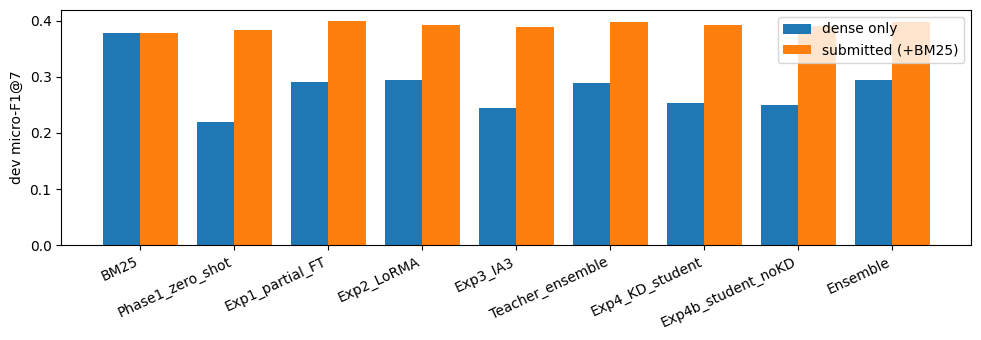

In [19]:
RES = pd.DataFrame(RESULTS)
RES.to_csv(WORK / 'results.csv', index=False)
pd.set_option('display.width', 250)
print(RES[['system', 'technique', 'dev_F1_dense', 'dev_P', 'dev_R', 'dev_F1_submitted', 'alpha', 'trainable_M', 'total_M', 'train_min', 'peak_gb', 'ms_per_doc']].round(4).to_string(index=False))
try:
    import matplotlib.pyplot as plt
    sub = RES[RES.system.str.startswith(('BM25', 'Phase1', 'Exp', 'Teacher', 'Ensemble'))]
    fig, ax = plt.subplots(figsize=(10, 3.5)); x = np.arange(len(sub))
    ax.bar(x - 0.2, sub.dev_F1_dense, 0.4, label='dense only'); ax.bar(x + 0.2, sub.dev_F1_submitted, 0.4, label='submitted (+BM25)')
    ax.set_xticks(x); ax.set_xticklabels(sub.system, rotation=25, ha='right'); ax.set_ylabel('dev micro-F1@7'); ax.legend(); plt.tight_layout()
    plt.savefig(WORK / 'results.png', dpi=130); plt.show()
except Exception as e:
    print('plot skipped:', e)

## 13. Failure analysis (dev, ensemble)

In [20]:
S_best = fuse(ENS_D['dev'], BM25['dev'], E_ALPHA); pred = topk_ids(S_best, 'dev')
rows = []
for i, q in enumerate(DATA['dev']['qids']):
    g = set(DATA['dev']['gold'][q]); hits = len(set(pred[q]) & g)
    order = np.argsort(-S_best[i]); rank = {DATA['dev']['cids'][j]: r for r, j in enumerate(order)}
    rows.append(dict(qid=q, n_gold=len(g), hits=hits, q_tokens=len(TOKS['dev']['q'][i]),
                     recall_at_20=len([c for c in g if rank[c] < 20]) / max(len(g), 1),
                     recall_at_100=len([c for c in g if rank[c] < 100]) / max(len(g), 1),
                     median_gold_rank=float(np.median([rank[c] for c in g])) if g else np.nan))
FA = pd.DataFrame(rows)
print('hits@7 per query:', FA.hits.value_counts().sort_index().to_dict())
print(f'queries with zero hits: {(FA.hits == 0).mean():.0%} | mean recall@20 {FA.recall_at_20.mean():.3f} | recall@100 {FA.recall_at_100.mean():.3f}')
FA['gold_bucket'] = pd.cut(FA.n_gold, [0, 3, 7, 15, 1000], labels=['1-3', '4-7', '8-15', '>15'])
FA['len_bucket'] = pd.qcut(FA.q_tokens.rank(method='first'), 3, labels=['short', 'medium', 'long'])
print(FA.groupby('gold_bucket', observed=True)[['hits', 'recall_at_20']].mean().round(3))
print(FA.groupby('len_bucket', observed=True)[['hits', 'recall_at_20']].mean().round(3))
# per-system agreement: how often does each system find gold the others miss?
PX = {n: topk_ids(BM25['dev'] if n == 'BM25' else DENSE[n]['dev'], 'dev') for n in ens_names + ['BM25']}
for n in PX:
    uniq = sum(len((set(PX[n][q]) & set(DATA['dev']['gold'][q])) - set().union(*[set(PX[m][q]) for m in PX if m != n])) for q in DATA['dev']['qids'])
    print(f'{n:18s} finds {uniq} gold cases that no other system ranks in its top 7')
worst = FA.sort_values(['hits', 'median_gold_rank'], ascending=[True, False]).head(3)
for _, w in worst.iterrows():
    i = DATA['dev']['qids'].index(w.qid); top = pred[w.qid][0]; g0 = DATA['dev']['gold'][w.qid][0] if DATA['dev']['gold'][w.qid] else None
    print(f"\nquery {w.qid} | gold {w.n_gold} | median gold rank {w.median_gold_rank:.0f}\n  QUERY : {DATA['dev']['qtext'][i][:250]!r}"
          f"\n  TOP-1 (wrong): {DATA['dev']['ctext'][DATA['dev']['cidx'][top]][:200]!r}"
          + (f"\n  MISSED GOLD  : {DATA['dev']['ctext'][DATA['dev']['cidx'][g0]][:200]!r}" if g0 else ''))
FA.to_csv(WORK / 'failure_analysis_dev.csv', index=False)

hits@7 per query: {0: 7, 1: 29, 2: 20, 3: 17, 4: 14, 5: 13, 6: 9, 7: 9}
queries with zero hits: 6% | mean recall@20 0.671 | recall@100 0.818
              hits  recall_at_20
gold_bucket                     
1-3          1.275         0.804
4-7          2.872         0.639
8-15         4.920         0.654
>15          5.143         0.410
             hits  recall_at_20
len_bucket                     
short       1.897         0.770
medium      3.154         0.693
long        4.025         0.553
Exp1_partial_FT    finds 6 gold cases that no other system ranks in its top 7
Exp2_LoRMA         finds 13 gold cases that no other system ranks in its top 7
Exp3_IA3           finds 15 gold cases that no other system ranks in its top 7
Exp4_KD_student    finds 22 gold cases that no other system ranks in its top 7
BM25               finds 99 gold cases that no other system ranks in its top 7

query 0000477921 | gold 1 | median gold rank 666
  QUERY : '<NAME>, J.  1. Now that we have had the docume

## 14. Final check of the zips

In [21]:
for p in sorted(SUB_DIR.glob('*.zip')):
    with zipfile.ZipFile(p) as z:
        names = z.namelist(); pred = json.loads(z.read('prediction.json'))
    validate(pred)
    assert names == ['prediction.json'], names
    sysname = {'sub1_bm25': 'BM25', 'sub2_partial_ft': 'Exp1_partial_FT', 'sub3_lorma': 'Exp2_LoRMA', 'sub4_ia3': 'Exp3_IA3',
               'sub5_kd_student': 'Exp4_KD_student', 'sub6_ensemble': 'Ensemble'}.get(p.stem)
    f1 = RES.set_index('system').dev_F1_submitted.get(sysname, np.nan) if sysname else np.nan
    print(f'{p.name:24s} OK  {len(pred)} queries x 7 | prediction.json at root | dev F1@7 {f1:.4f}')
print('\nDownload from the Output panel: /kaggle/working/submissions/*.zip  (+ results.csv, results.png, failure_analysis_dev.csv)')

sub1_bm25.zip            OK  237 queries x 7 | prediction.json at root | dev F1@7 0.3780
sub2_partial_ft.zip      OK  237 queries x 7 | prediction.json at root | dev F1@7 0.3991
sub3_lorma.zip           OK  237 queries x 7 | prediction.json at root | dev F1@7 0.3924
sub4_ia3.zip             OK  237 queries x 7 | prediction.json at root | dev F1@7 0.3880
sub5_kd_student.zip      OK  237 queries x 7 | prediction.json at root | dev F1@7 0.3924
sub6_ensemble.zip        OK  237 queries x 7 | prediction.json at root | dev F1@7 0.3980

Download from the Output panel: /kaggle/working/submissions/*.zip  (+ results.csv, results.png, failure_analysis_dev.csv)


## 15. Report skeleton (§13.5) — fill in with the numbers printed above

**Setup.** Phase-1 checkpoint, layout check (next-token loss vs Phase-1 val loss), chunking (`N_CHUNKS_EVAL × CHUNK_LEN`), pooling, contrastive objective (InfoNCE, τ = 0.05, in-batch + 1 BM25 hard negative, false negatives masked), `STEPS` steps per experiment, model selection on dev, test only for submission.

1. **Adaptation techniques vs retrieval quality** — compare Exp1 (partial FT), Exp2 (LoRMA), Exp3 (IA³) on dev F1/P/R (dense-only and fused). Relate quality to trainable parameters (results table).
2. **Transfer of Phase-1 representations** — zero-shot row vs adapted rows. A next-token LM is not trained to put relevant cases close together; contrastive adaptation is what turns it into a retriever.
3. **Pooling & document representation** — ablation table: 1 chunk vs N chunks, mean vs position-weighted mean vs last token.
4. **Similarity & ranking objectives** — cosine + InfoNCE (listwise over the batch) vs KD's KL over the teacher's list; effect of fusing with BM25 (α).
5. **Hard negatives / sampling** — BM25 negatives are lexically similar but not cited; false-negative masking matters because some cases are relevant to several queries.
6. **Long documents** — median length vs tokens actually encoded (printed in §3); recall@100 in the failure analysis.
7. **Failure patterns** — zero-hit queries, buckets by number of gold cases and query length, worst examples, which system finds what.
8. **Knowledge distillation** — teacher vs KD student vs no-KD student: F1, params (≈ half the layers), ms/doc, training time.
9. **Quality vs size/memory/speed** — columns `trainable_M`, `total_M`, `peak_gb`, `ms_per_doc`, `train_min`.
10. **Why techniques may not transfer from other legal tasks** — classification/NLI fine-tuning optimises a label head on one document; PCR needs a metric space over pairs of very long documents, so parameter-light methods that work for classification (IA³, few vectors) may under-fit the geometry change retrieval needs, whereas methods that touch attention projections (LoRMA, partial FT) can reshape it.